In [1]:
%pip install -q yfinance pandas numpy scikit-learn xgboost lightgbm "flaml[automl]" shap plotly matplotlib streamlit

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

TICKERS   = ["TCS.NS", "RELIANCE.NS", "INFY.NS", "HDFCBANK.NS",
             "ICICIBANK.NS", "ITC.NS", "LT.NS", "SBIN.NS"]
INDEX     = "^NSEI"
START     = "2012-01-01"
END       = None
HORIZON   = 5          # predict direction of next N trading days
TEST_FRAC = 0.30
TC        = 0.001      # transaction cost per position change
BUY_THR   = 0.55
AVOID_THR = 0.45
AUTOML_TIME_BUDGET = 120
SEED      = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
np.random.seed(SEED)

Matplotlib is building the font cache; this may take a moment.


In [2]:
def download_ohlcv(ticker):
    import yfinance as yf
    df = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    return df

raw = {}
for t in [INDEX] + TICKERS:
    raw[t] = download_ohlcv(t)
    print(f"{t:14s} {len(raw[t]):5d} rows  {raw[t].index.min().date()} -> {raw[t].index.max().date()}")

^NSEI           3631 rows  2012-01-03 -> 2026-10-15
TCS.NS          3648 rows  2012-01-02 -> 2026-10-15
RELIANCE.NS     3648 rows  2012-01-02 -> 2026-10-15
INFY.NS         3648 rows  2012-01-02 -> 2026-10-15
HDFCBANK.NS     3648 rows  2012-01-02 -> 2026-10-15
ICICIBANK.NS    3648 rows  2012-01-02 -> 2026-10-15
ITC.NS          3648 rows  2012-01-02 -> 2026-10-15
LT.NS           3648 rows  2012-01-02 -> 2026-10-15
SBIN.NS         3648 rows  2012-01-02 -> 2026-10-15


In [3]:
def clean_ohlcv(df, name=""):
    n0 = len(df)
    df = df[~df.index.duplicated(keep="last")].sort_index()
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df[(df[["Open", "High", "Low", "Close"]] > 0).all(axis=1) | df["Close"].isna()]
    df = df.ffill(limit=3).dropna()
    df = df[df["Volume"] >= 0]
    df["High"] = df[["Open", "High", "Low", "Close"]].max(axis=1)
    df["Low"]  = df[["Open", "High", "Low", "Close"]].min(axis=1)
    bad = df["Close"].pct_change().abs() > 0.40
    df = df[~bad]
    print(f"{name:14s} kept {len(df)}/{n0} rows, dropped {bad.sum()} outlier days")
    return df

data = {t: clean_ohlcv(df, t) for t, df in raw.items()}
index_df = data.pop(INDEX)
stocks = data

^NSEI          kept 3631/3631 rows, dropped 0 outlier days
TCS.NS         kept 3648/3648 rows, dropped 0 outlier days
RELIANCE.NS    kept 3648/3648 rows, dropped 0 outlier days
INFY.NS        kept 3648/3648 rows, dropped 0 outlier days
HDFCBANK.NS    kept 3648/3648 rows, dropped 0 outlier days
ICICIBANK.NS   kept 3648/3648 rows, dropped 0 outlier days
ITC.NS         kept 3648/3648 rows, dropped 0 outlier days
LT.NS          kept 3648/3648 rows, dropped 0 outlier days
SBIN.NS        kept 3648/3648 rows, dropped 0 outlier days


In [4]:
idx_dates = index_df.index
split_pos = int(len(idx_dates) * (1 - TEST_FRAC))
SPLIT_DATE = idx_dates[split_pos]
PURGE_DATE = idx_dates[split_pos - HORIZON]
print("Train:", idx_dates[0].date(), "->", PURGE_DATE.date())
print("Test: ", SPLIT_DATE.date(), "->", idx_dates[-1].date())

Train: 2012-01-03 -> 2022-05-12
Test:  2022-05-19 -> 2026-10-15


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

ir = index_df["Close"].pct_change()
mf = pd.DataFrame({
    "ret_63d": index_df["Close"].pct_change(63),
    "vol_21d": ir.rolling(21).std() * np.sqrt(252),
}).dropna()

mf_train = mf[mf.index < PURGE_DATE]
scaler = StandardScaler().fit(mf_train)
Z_train = scaler.transform(mf_train)

rows, models = [], {}
for k in (3, 4, 5):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_train)
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=SEED).fit(Z_train)
    for name, m in (("KMeans", km), ("GMM", gm)):
        lab = m.predict(Z_train)
        sil = silhouette_score(Z_train, lab, sample_size=min(3000, len(lab)), random_state=SEED)
        rows.append({"method": name, "k": k, "silhouette": sil})
        models[(name, k)] = m
reg_cmp = pd.DataFrame(rows).sort_values("silhouette", ascending=False)
display(reg_cmp)
best = reg_cmp.iloc[0]
regime_model = models[(best["method"], int(best["k"]))]
print("Selected:", best["method"], "k =", int(best["k"]))

,method,k,silhouette
0,KMeans,3,0.438239
1,GMM,3,0.423215
2,KMeans,4,0.414966
4,KMeans,5,0.412219
3,GMM,4,0.402635
5,GMM,5,0.394258


Selected: KMeans k = 3


,ret_63d,vol_21d,name
c,,,
0,-0.034915,0.174773,Bearish / High-Vol
1,0.085280,0.122895,Bullish / Low-Vol
2,-0.270955,0.667111,Bearish / High-Vol


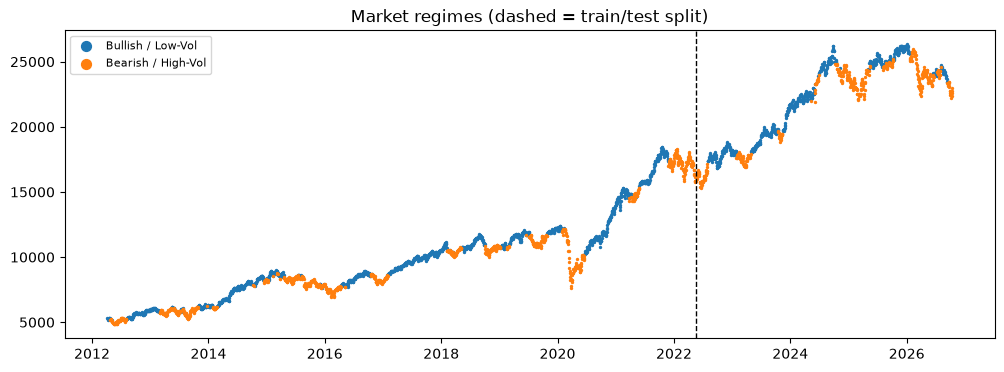

In [6]:
train_lab = regime_model.predict(Z_train)
stats = mf_train.assign(c=train_lab).groupby("c").mean()
vol_med = mf_train["vol_21d"].median()
ret_thr = 0.25 * mf_train["ret_63d"].std()

def name_cluster(r):
    trend = "Bullish" if r.ret_63d > ret_thr else ("Bearish" if r.ret_63d < -ret_thr else "Sideways")
    vol = "High-Vol" if r.vol_21d > vol_med else "Low-Vol"
    return f"{trend} / {vol}"

cluster_names = {c: name_cluster(r) for c, r in stats.iterrows()}
stats["name"] = pd.Series(cluster_names)
display(stats)

def add_regime_flags(reg):
    reg["reg_bull"] = reg["reg_name"].str.startswith("Bullish").astype(int)
    reg["reg_bear"] = reg["reg_name"].str.startswith("Bearish").astype(int)
    reg["reg_highvol"] = reg["reg_name"].str.endswith("High-Vol").astype(int)
    return reg

regime = pd.DataFrame(index=mf.index)
regime["reg_name"] = pd.Series(regime_model.predict(scaler.transform(mf)), index=mf.index).map(cluster_names)
regime = add_regime_flags(regime)

fig, ax = plt.subplots(figsize=(12, 4))
px_ = index_df["Close"].reindex(regime.index)
for nm in regime["reg_name"].unique():
    m = regime["reg_name"] == nm
    ax.scatter(px_.index[m], px_[m], s=2, label=nm)
ax.axvline(SPLIT_DATE, color="k", ls="--", lw=1)
ax.set_title("Market regimes (dashed = train/test split)")
ax.legend(markerscale=5, fontsize=8)
plt.show()

In [7]:
def rsi(close, n=14):
    d = close.diff()
    up, dn = d.clip(lower=0), -d.clip(upper=0)
    ru, rd = up.ewm(alpha=1/n, adjust=False).mean(), dn.ewm(alpha=1/n, adjust=False).mean()
    return 100 - 100 / (1 + ru / rd.replace(0, np.nan))

def atr(df, n=14):
    pc = df["Close"].shift()
    tr = pd.concat([df["High"] - df["Low"], (df["High"] - pc).abs(), (df["Low"] - pc).abs()], axis=1).max(axis=1)
    return tr.ewm(alpha=1/n, adjust=False).mean()

mkt_ret_21 = index_df["Close"].pct_change(21)

def build_features(df):
    c, v = df["Close"], df["Volume"]
    r1 = c.pct_change()
    f = pd.DataFrame(index=df.index)
    for n in (1, 5, 21, 63, 126):
        f[f"ret_{n}d"] = c.pct_change(n)
    for n in (10, 20, 50, 100):
        f[f"px_ma{n}"] = c / c.rolling(n).mean() - 1
    f["ma20_ma50"] = c.rolling(20).mean() / c.rolling(50).mean() - 1
    f["rsi_14"] = rsi(c)
    ema12, ema26 = c.ewm(span=12, adjust=False).mean(), c.ewm(span=26, adjust=False).mean()
    macd = ema12 - ema26
    f["macd"] = macd / c
    f["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    for n in (10, 21, 63):
        f[f"vol_{n}"] = r1.rolling(n).std() * np.sqrt(252)
    f["atr_pct"] = atr(df) / c
    bb_m, bb_s = c.rolling(20).mean(), c.rolling(20).std()
    f["bb_pos"] = (c - bb_m) / (2 * bb_s.replace(0, np.nan))
    f["vol_chg_1d"] = v.pct_change().replace([np.inf, -np.inf], np.nan).fillna(0).clip(-5, 5)
    f["vol_ratio_20"] = v / v.rolling(20).mean().replace(0, np.nan)
    f["vol_ratio_5_20"] = v.rolling(5).mean() / v.rolling(20).mean().replace(0, np.nan)
    f["rel_mkt_21d"] = f["ret_21d"] - mkt_ret_21.reindex(df.index)
    f["dd_60"] = c / c.rolling(60).max() - 1
    f["sharpe_60"] = r1.rolling(60).mean() / r1.rolling(60).std().replace(0, np.nan) * np.sqrt(252)
    f["var95_60"] = r1.rolling(60).quantile(0.05)
    fwd = c.shift(-HORIZON) / c - 1
    f["fwd_ret"] = fwd
    f["target"] = np.where(fwd.isna(), np.nan, (fwd > 0).astype(float))
    return f

frames = []
for t, df in stocks.items():
    f = build_features(df)
    f["ticker"] = t
    f = f.join(regime[["reg_name", "reg_bull", "reg_bear", "reg_highvol"]], how="inner")
    frames.append(f.rename_axis("Date"))
panel = pd.concat(frames).reset_index().sort_values(["Date", "ticker"]).reset_index(drop=True)

META = ["Date", "ticker", "reg_name", "fwd_ret", "target"]
FEATURES = [c for c in panel.columns if c not in META]
panel = panel.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)
print(panel.shape, len(FEATURES), "features")

(28056, 33) 28 features


In [8]:
train = panel[(panel["Date"] < PURGE_DATE) & panel["target"].notna()].copy()
test  = panel[panel["Date"] >= SPLIT_DATE].copy()
test_lab = test[test["target"].notna()]

X_tr, y_tr = train[FEATURES], train["target"].astype(int)
X_te, y_te = test_lab[FEATURES], test_lab["target"].astype(int)
print(X_tr.shape, X_te.shape)

(19296, 28) (8680, 28)


In [9]:
from flaml import AutoML

automl = AutoML()
automl.fit(
    X_train=X_tr, y_train=y_tr,
    task="classification", metric="roc_auc",
    estimator_list=["lgbm", "xgboost", "rf", "extra_tree", "lrl1"],
    eval_method="holdout", split_type="time", split_ratio=0.2,
    time_budget=AUTOML_TIME_BUDGET, seed=SEED, verbose=1,
)
print("Best model:", automl.best_estimator)
print("Best config:", automl.best_config)
board = pd.DataFrame({
    "estimator": list(automl.best_loss_per_estimator.keys()),
    "val_AUC": [1 - v for v in automl.best_loss_per_estimator.values()],
}).sort_values("val_AUC", ascending=False)
display(board)

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Users/atishi/Desktop/C++ Program/automl-stock-project/.venv/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <89AD948E-E564-3266-867D-7AF89D6488F0> /Users/atishi/Desktop/C++ Program/automl-stock-project/.venv/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes